# Практическая работа № 9. Метод опорных векторов (SVM)

**Цель:** исследовать влияние ядровой функции и гиперпараметра `C` на поведение классификатора SVM.

В этой работе используем учебный двумерный датасет `make_moons`, чтобы на графиках увидеть границы решений. Все признаки обязательно масштабируем с помощью `StandardScaler`.

## 1. Импорт библиотек и подготовка данных

`make_moons` создаёт два класса точек в форме двух полумесяцев. Такая форма удобна для сравнения прямой линейной границы и нелинейной границы RBF.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

X, y = make_moons(n_samples=500, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Размер X:", X.shape)
print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер X: (500, 2)
Размер обучающей выборки: (375, 2)
Размер тестовой выборки: (125, 2)


## 2. Почему нужно масштабирование?

SVM чувствителен к масштабу признаков. Если один признак измеряется сотнями, а другой десятыми, модель может уделять им разное внимание только из-за единиц измерения.

`StandardScaler` приводит признаки к сопоставимому масштабу. Используем `Pipeline`, чтобы масштабирование обучалось только на тренировочных данных и затем одинаково применялось к тестовым данным.

In [2]:
def create_svm(kernel="linear", C=1.0, gamma="scale"):
    return make_pipeline(
        StandardScaler(),
        SVC(kernel=kernel, C=C, gamma=gamma)
    )

## 3. Вспомогательная функция для границы решения

Цветная область показывает, какой класс предсказывает модель в каждой точке плоскости. Чёрная линия — граница между классами.

In [3]:
def plot_decision_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.7, X[:, 0].max() + 0.7
    y_min, y_max = X[:, 1].min() - 0.7, X[:, 1].max() + 0.7

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 350),
        np.linspace(y_min, y_max, 350)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.22, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1.4)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
               edgecolors="black", s=24)
    ax.set_title(title)
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

## 4. Линейное ядро

Линейное ядро (`kernel="linear"`) пытается разделить классы прямой линией. Оно подходит, если классы можно достаточно хорошо разделить прямой границей.

Accuracy для linear: 0.824


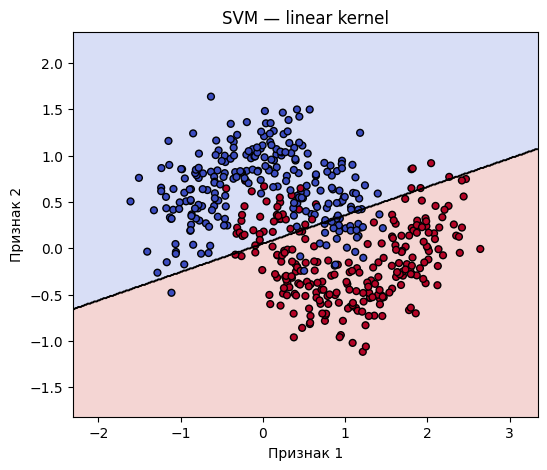

In [4]:
svm_linear = create_svm(kernel="linear", C=1.0)
svm_linear.fit(X_train, y_train)

linear_pred = svm_linear.predict(X_test)
print("Accuracy для linear:", round(accuracy_score(y_test, linear_pred), 3))

fig, ax = plt.subplots(figsize=(6, 5))
plot_decision_boundary(ax, svm_linear, X, y, "SVM — linear kernel")
plt.show()

## 5. RBF-ядро

RBF (`kernel="rbf"`) может строить нелинейную, изогнутую границу. Это полезно, когда классы имеют сложную форму и их нельзя хорошо разделить одной прямой.

Accuracy для RBF: 0.944


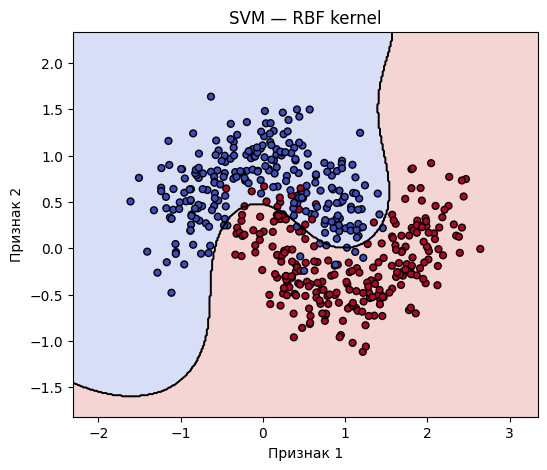

In [5]:
svm_rbf = create_svm(kernel="rbf", C=1.0)
svm_rbf.fit(X_train, y_train)

rbf_pred = svm_rbf.predict(X_test)
print("Accuracy для RBF:", round(accuracy_score(y_test, rbf_pred), 3))

fig, ax = plt.subplots(figsize=(6, 5))
plot_decision_boundary(ax, svm_rbf, X, y, "SVM — RBF kernel")
plt.show()

## 6. Сравнение двух ядер

Сравним качество на одной и той же тестовой выборке. Accuracy — доля правильных ответов модели.

In [6]:
print(f"Linear accuracy: {accuracy_score(y_test, linear_pred):.3f}")
print(f"RBF accuracy:    {accuracy_score(y_test, rbf_pred):.3f}")

Linear accuracy: 0.824
RBF accuracy:    0.944


## 7. Влияние параметра C

`C` управляет тем, насколько сильно модель штрафует себя за ошибки на обучающих данных.

- Малое `C` (например, 0.1): модель допускает больше ошибок и обычно строит более простую, сглаженную границу.
- Большое `C` (например, 10): модель сильнее старается правильно классифицировать обучающие точки; граница может стать сложнее, а риск переобучения — выше.

Сравним два значения для RBF-ядра.

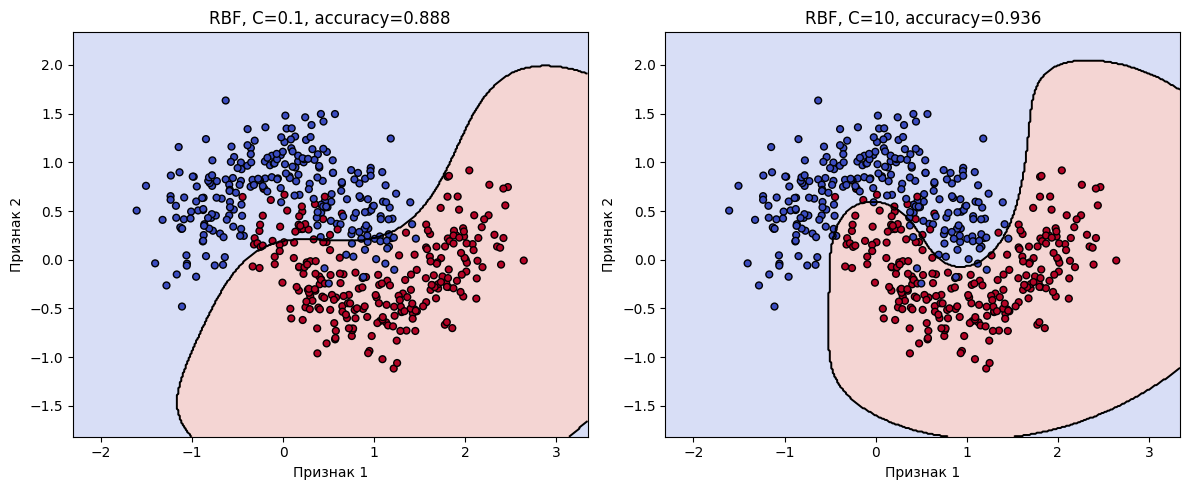

In [7]:
C_values = [0.1, 10]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, c_value in zip(axes, C_values):
    model = create_svm(kernel="rbf", C=c_value)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    score = accuracy_score(y_test, predictions)

    plot_decision_boundary(
        ax, model, X, y,
        f"RBF, C={c_value}, accuracy={score:.3f}"
    )

plt.tight_layout()
plt.show()

## 8. Влияние параметра gamma

`gamma` определяет, насколько далеко распространяется влияние одной обучающей точки. Малое значение обычно даёт более плавную границу, а большое — более локальную и сложную. Проверим два значения при одинаковом `C=1`.


gamma=0.1: accuracy=0.856
gamma=10: accuracy=0.952


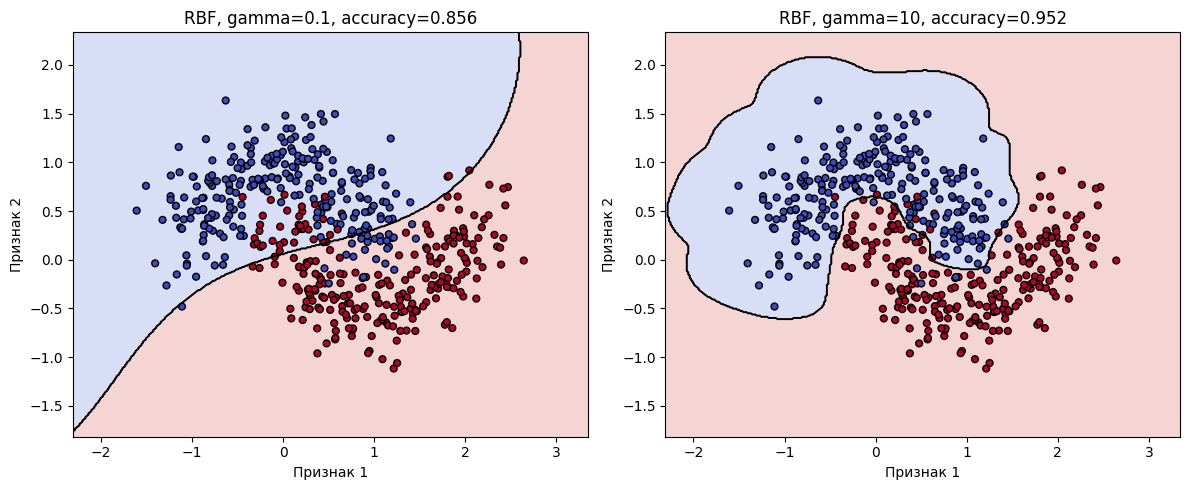

In [8]:
gamma_values = [0.1, 10]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, gamma_value in zip(axes, gamma_values):
    model = create_svm(kernel="rbf", C=1.0, gamma=gamma_value)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    score = accuracy_score(y_test, predictions)
    print(f"gamma={gamma_value}: accuracy={score:.3f}")
    plot_decision_boundary(
        ax, model, X, y,
        f"RBF, gamma={gamma_value}, accuracy={score:.3f}"
    )

plt.tight_layout()
plt.show()


**Что наблюдать:** при маленьком `gamma` граница обычно более плавная. При большом `gamma` влияние каждой точки становится более локальным, поэтому граница может сильнее изгибаться. Сравни также Accuracy, но не делай вывод только по одной метрике.


## 9. Дополнительная оценка модели

In [9]:
print(classification_report(
    y_test, rbf_pred,
    target_names=["Класс 0", "Класс 1"]
))

              precision    recall  f1-score   support

     Класс 0       0.92      0.97      0.95        63
     Класс 1       0.97      0.92      0.94        62

    accuracy                           0.94       125
   macro avg       0.95      0.94      0.94       125
weighted avg       0.95      0.94      0.94       125



## 10. Выводы

1. Линейное ядро строит прямую границу. Для данных в форме двух полумесяцев такая граница обычно недостаточно гибкая.
2. RBF-ядро строит нелинейную границу и лучше подходит для сложной формы `make_moons`.
3. Малое значение `C` допускает больше ошибок на обучении и стремится к более простой границе.
4. Большое значение `C` сильнее штрафует ошибки на обучении; граница может стать сложнее.
5. Перед обучением SVM признаки необходимо масштабировать. В работе это сделано с помощью `StandardScaler` внутри `Pipeline`.

**Примечание:** в сообщении не был приложен основной рабочий датасет курса. Поэтому для визуализации и демонстрации использован `make_moons`. Если преподаватель требует оценку именно на основном датасете, его нужно добавить и заменить блок загрузки данных.
6. Параметр `gamma` задаёт радиус влияния точек: большое значение обычно делает границу более локальной и сложной.
